# Documentation du jeu de données NASA C-MAPSS

Le jeu de données se compose de **26 colonnes d'origine** (séparées par des espaces) ainsi que d'une **27ᵉ colonne (`RUL`)** calculée lors du prétraitement pour l'apprentissage supervisé.

---

## 1. Index et Identifiants (Colonnes 1 et 2)

| Nom de la colonne | Type | Description |
| :--- | :--- | :--- |
| `unit_number` | Entier (`int`) | **ID unique du moteur / de l'équipement.** Identifie l'unité suivie au fil du temps (ex: Moteur 1, Moteur 2, etc.). |
| `time_in_cycles` | Entier (`int`) | **Horodatage / Temps écoulé.** Représente le nombre de cycles de vol accomplis depuis le début de la mesure ($1, 2, 3 \dots$). |

---

## 2. Réglages Opérationnels (Colonnes 3 à 5)

Ces paramètres définissent les conditions d'exploitation et l'environnement de vol de l'avion à un instant donné.

| Nom de la colonne | Type | Description |
| :--- | :--- | :--- |
| `setting_1` | Flottant (`float`) | **Altitude de vol** (en milliers de pieds). |
| `setting_2` | Flottant (`float`) | **Nombre de Mach / Vitesse** de l'appareil. |
| `setting_3` | Flottant (`float`) | **Température totale à l'entrée de la veine d'air** (conditions ambiantes). |

> **Note :** Dans le sous-ensemble `FD001`, ces 3 réglages sont quasi-constants. Dans `FD002` et `FD004`, ils varient pour simuler 6 régimes de vol différents.

---

## 3. Capteurs Physiques du Réacteur (Colonnes 6 à 26)

Ces variables mesurent la réponse thermodynamique, la pression et la vitesse de rotation des différents sous-ensembles du turboréacteur :

| Nom de la colonne | Libellé technique (Doc NASA) | Description physique | Unité de mesure |
| :--- | :--- | :--- | :--- |
| `sensor_1` | **T2** | Température totale à l'entrée de la soufflante (*Fan inlet*) | $^\circ\text{R}$ (Rankine) |
| `sensor_2` | **T24** | Température totale à la sortie du compresseur basse pression (LPC) | $^\circ\text{R}$ |
| `sensor_3` | **T30** | Température totale à la sortie du compresseur haute pression (HPC) | $^\circ\text{R}$ |
| `sensor_4` | **T50** | Température totale à la sortie de la turbine basse pression (LPT) | $^\circ\text{R}$ |
| `sensor_5` | **P2** | Pression de pression totale à l'entrée de la soufflante | $\text{psia}$ |
| `sensor_6` | **P15** | Pression totale dans le canal de dérivation (*Bypass duct*) | $\text{psia}$ |
| `sensor_7` | **P30** | Pression totale à la sortie du compresseur haute pression (HPC) | $\text{psia}$ |
| `sensor_8` | **Nf** | Vitesse de rotation physique de la soufflante (*Fan speed*) | $\text{rpm}$ (tr/min) |
| `sensor_9` | **Nc** | Vitesse de rotation physique du cœur / de l'arbre HP (*Core speed*) | $\text{rpm}$ (tr/min) |
| `sensor_10` | **epr** | Ratio de pression du moteur (*Engine Pressure Ratio*) | Sans unité |
| `sensor_11` | **Ps30** | Pression statique à la sortie du compresseur haute pression (HPC) | $\text{psia}$ |
| `sensor_12` | **phi** | Ratio débit de carburant sur pression à la sortie du compresseur | $\text{pps/psi}$ |
| `sensor_13` | **NRf** | Vitesse corrélée de la soufflante | $\text{rpm}$ |
| `sensor_14` | **NRc** | Vitesse corrélée du cœur (*Core speed*) | $\text{rpm}$ |
| `sensor_15` | **BPR** | Taux de dilution (*Bypass Ratio*) | Sans unité |
| `sensor_16` | **farB** | Ratio brûleur carburant/air (*Burner fuel-air ratio*) | Sans unité |
| `sensor_17` | **htBleed** | Enthalpie de prélèvement d'air (*Bleed Enthalpy*) | -- |
| `sensor_18` | **Nf_dmd** | Vitesse de rotation demandée pour la soufflante | $\text{rpm}$ |
| `sensor_19` | **PCNfR_dmd** | Régime corrigé demandé pour la soufflante | $\%$ |
| `sensor_20` | **W31** | Débit de prélèvement d'air de refroidissement haute pression | $\text{lbm/s}$ |
| `sensor_21` | **W32** | Débit de prélèvement d'air de refroidissement basse pression | $\text{lbm/s}$ |

---

## 4. Variable Cible / Target (Colonne 27 - Générée)

| Nom de la colonne | Type | Description |
| :--- | :--- | :--- |
| `RUL` | Entier (`int`) | **Remaining Useful Life (Durée de vie résiduelle).** Représente le nombre exact de cycles de vol qu'il reste à l'équipement avant la panne irréversible ($\text{RUL} = 0$). |

---

### 💡 Astuce pour l'Analyse Exploratoire (EDA)

Dans `FD001`, plusieurs capteurs restent **strictement constants** tout au long des cycles de vol (ex: `sensor_1`, `sensor_5`, `sensor_10`, `sensor_16`, `sensor_18`, `sensor_19`). 

Comme ils ne contiennent aucune variance ni information sur la dégradation, **il faudra les supprimer** lors de la phase de sélection de variables (*Feature Selection*) pour ne garder que les capteurs dynamiques qui dérivent avec l'usure (comme `sensor_2`, `sensor_3`, `sensor_4`, `sensor_7`, `sensor_11`, etc.).

In [11]:
import os
import pandas as pd

# Chemins des dossiers
RAW_DATA_DIR = os.path.join("..", "dataset", "raw")
PROCESSED_DATA_DIR = os.path.join("..", "data", "processed")

# Noms standardisés des colonnes selon la documentation NASA
INDEX_COLS = ["unit_number", "time_in_cycles"]
SETTING_COLS = ["setting_1", "setting_2", "setting_3"]
SENSOR_COLS = [f"sensor_{i}" for i in range(1, 22)]
COLUMN_NAMES = INDEX_COLS + SETTING_COLS + SENSOR_COLS

In [12]:
def load_cmapss_data(dataset_id: str = "FD001") -> pd.DataFrame:
    """Charge et affiche les données brutes d'entraînement C-MAPSS."""
    filename = f"train_{dataset_id}.txt"
    file_path = os.path.join(RAW_DATA_DIR, filename)
    print(f"Chargement de {file_path}...")

    df = pd.read_csv(file_path, sep=r"\s+", header=None, names=COLUMN_NAMES)

    print("Aperçu du dataset principal avant traitement :")
    print(f"Dimensions : {df.shape}")
    display(df.head())
    return df


# Chargement et affichage du dataset brut FD001
df_raw = load_cmapss_data("FD001")

Chargement de ..\dataset\raw\train_FD001.txt...
Aperçu du dataset principal avant traitement :
Dimensions : (20631, 26)


,unit_number,time_in_cycles,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [13]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   unit_number     20631 non-null  int64  
 1   time_in_cycles  20631 non-null  int64  
 2   setting_1       20631 non-null  float64
 3   setting_2       20631 non-null  float64
 4   setting_3       20631 non-null  float64
 5   sensor_1        20631 non-null  float64
 6   sensor_2        20631 non-null  float64
 7   sensor_3        20631 non-null  float64
 8   sensor_4        20631 non-null  float64
 9   sensor_5        20631 non-null  float64
 10  sensor_6        20631 non-null  float64
 11  sensor_7        20631 non-null  float64
 12  sensor_8        20631 non-null  float64
 13  sensor_9        20631 non-null  float64
 14  sensor_10       20631 non-null  float64
 15  sensor_11       20631 non-null  float64
 16  sensor_12       20631 non-null  float64
 17  sensor_13       20631 non-null 

## 2. Exploration, nettoyage et sélection des signaux

On contrôle la qualité des données, retire les capteurs constants et conserve l'ordre chronologique par moteur. FD001 ne contient qu'un régime de fonctionnement. La baseline Random Forest ne nécessite pas de standardisation; si un modèle sensible à l'échelle est ajouté, son scaler devra être ajusté sur les seuls moteurs d'entraînement.

In [14]:
# Contrôles de qualité et sélection des variables
missing_values = df_raw.isna().sum()
print(f"Lignes dupliquées : {df_raw.duplicated().sum()}")
print(f"Valeurs manquantes : {int(missing_values.sum())}")

sensor_variance = df_raw[SENSOR_COLS].var().sort_values()
constant_sensors = sensor_variance[sensor_variance == 0].index.tolist()
selected_sensors = [sensor for sensor in SENSOR_COLS if sensor not in constant_sensors]
selected_settings = [column for column in SETTING_COLS if df_raw[column].nunique() > 1]

print(f"Capteurs constants retirés ({len(constant_sensors)}) : {constant_sensors}")
print(f"Capteurs conservés ({len(selected_sensors)}) : {selected_sensors}")
print(f"Réglages variables : {selected_settings}")
display(sensor_variance.to_frame(name="variance"))

df_raw = df_raw.sort_values(["unit_number", "time_in_cycles"]).reset_index(drop=True)

Lignes dupliquées : 0
Valeurs manquantes : 0
Capteurs constants retirés (4) : ['sensor_1', 'sensor_10', 'sensor_19', 'sensor_18']
Capteurs conservés (17) : ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_20', 'sensor_21']
Réglages variables : ['setting_1', 'setting_2']


,variance
sensor_1,0.000000e+00
sensor_10,0.000000e+00
sensor_19,0.000000e+00
sensor_18,0.000000e+00
sensor_16,1.203765e-35
sensor_5,2.840037e-29
sensor_6,1.929279e-06
sensor_15,1.406628e-03
sensor_8,5.038938e-03
sensor_13,5.172330e-03


## 3. Ingénierie des caractéristiques temporelles

La cible d'entraînement est la RUL exacte. Pour chaque moteur, on ajoute des différences par rapport au cycle précédent, un écart à la première mesure et des moyennes/écarts-types glissants causaux (fenêtres 5, 10 et 20). Les fenêtres ne regardent jamais les cycles futurs. FD001 étant mono-régime, les réglages opérationnels sont constants ou quasi constants; ils sont conservés s'ils varient.

In [15]:
import numpy as np

DATASET_ID = "FD001"
ROLLING_WINDOWS = (5, 10, 20)

# Calcul de la RUL pour chaque cycle d'entraînement.
df_train = df_raw.copy()
df_train["RUL"] = (
    df_train.groupby("unit_number")["time_in_cycles"].transform("max")
    - df_train["time_in_cycles"]
)

# Écrit le jeu de données tabulaire traité pour les analyses ultérieures.
os.makedirs(PROCESSED_DATA_DIR, exist_ok=True)
processed_path = os.path.join(PROCESSED_DATA_DIR, f"train_{DATASET_ID}_processed.csv")
df_train.to_csv(processed_path, index=False)
print(f"Données avec RUL sauvegardées : {processed_path}")
display(df_train[["unit_number", "time_in_cycles", "RUL"]].head())


def create_temporal_features(data: pd.DataFrame) -> pd.DataFrame:
    """Construit des features causales, calculées séparément pour chaque moteur."""
    featured = data.sort_values(["unit_number", "time_in_cycles"]).reset_index(drop=True).copy()

    for sensor in selected_sensors:
        grouped = featured.groupby("unit_number", sort=False)[sensor]
        featured[f"{sensor}_delta"] = grouped.diff().fillna(0)
        featured[f"{sensor}_from_baseline"] = (
            featured[sensor] - grouped.transform("first")
        )

        for window in ROLLING_WINDOWS:
            rolling = grouped.transform(
                lambda values: values.rolling(window=window, min_periods=1).mean()
            )
            rolling_std = grouped.transform(
                lambda values: values.rolling(window=window, min_periods=2).std()
            )
            featured[f"{sensor}_mean_{window}"] = rolling
            featured[f"{sensor}_std_{window}"] = rolling_std.fillna(0)

    return featured


df_features = create_temporal_features(df_train)
FEATURE_COLUMNS = (
    selected_sensors
    + selected_settings
    + [
        column
        for column in df_features.columns
        if column.endswith("_delta")
        or column.endswith("_from_baseline")
        or "_mean_" in column
        or "_std_" in column
    ]
)

X = df_features[FEATURE_COLUMNS].replace([np.inf, -np.inf], np.nan).fillna(0)
y = df_features["RUL"]
groups = df_features["unit_number"]
print(f"Nombre de features : {len(FEATURE_COLUMNS)}")
print(f"Dimensions de X : {X.shape}")

Données avec RUL sauvegardées : ..\data\processed\train_FD001_processed.csv


,unit_number,time_in_cycles,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187


C:\Users\fredb\AppData\Local\Temp\ipykernel_17704\922853626.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  featured[f"{sensor}_mean_{window}"] = rolling
C:\Users\fredb\AppData\Local\Temp\ipykernel_17704\922853626.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  featured[f"{sensor}_std_{window}"] = rolling_std.fillna(0)
C:\Users\fredb\AppData\Local\Temp\ipykernel_17704\922853626.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor per

Nombre de features : 155
Dimensions de X : (20631, 155)


## 4. Modélisation et validation sans fuite de données

Baseline explicable : Random Forest pour la régression de RUL. La validation sépare des moteurs entiers avec `GroupShuffleSplit`; aucun cycle d'un même moteur ne peut se retrouver simultanément dans l'entraînement et la validation. Les arbres ne nécessitent pas de mise à l'échelle des variables.

In [16]:
import numpy as np

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GroupShuffleSplit


# ============================================================
# 1. NASA ASYMMETRIC SCORE
# ============================================================

def nasa_asymmetric_score(y_true, y_pred):
    """
    Pénalise les erreurs de prédiction du RUL de manière asymétrique.
    Plus le score est faible, mieux c'est.
    """

    error = np.asarray(y_pred) - np.asarray(y_true)

    penalties = np.where(
        error < 0,
        np.exp(-error / 13) - 1,
        np.exp(error / 10) - 1
    )

    return float(penalties.sum())


# ============================================================
# 2. SPLIT PAR MOTEUR
# ============================================================

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_indices, validation_indices = next(
    splitter.split(X, y, groups=groups)
)


X_train = X.iloc[train_indices]
X_validation = X.iloc[validation_indices]

y_train = y.iloc[train_indices]
y_validation = y.iloc[validation_indices]


train_units = set(groups.iloc[train_indices].unique())
validation_units = set(groups.iloc[validation_indices].unique())


# Vérification qu'aucun moteur n'est présent dans les deux ensembles
assert train_units.isdisjoint(validation_units), \
    "Fuite détectée : moteurs partagés entre les jeux."


print("=" * 60)
print("SPLIT DES DONNÉES")
print("=" * 60)

print(f"Moteurs entraînement : {len(train_units)}")
print(f"Moteurs validation   : {len(validation_units)}")


# ============================================================
# 3. MODÈLES
# ============================================================

models = {

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        max_features="sqrt",
        n_jobs=-1,
        random_state=42
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        max_features="sqrt",
        n_jobs=-1,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        min_samples_leaf=3,
        random_state=42
    ),

    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    )
}


# ============================================================
# 4. ENTRAÎNEMENT + ÉVALUATION
# ============================================================

results = []


for name, model in models.items():

    print("\n" + "=" * 60)
    print(f"MODÈLE : {name}")
    print("=" * 60)

    # Entraînement
    # Fit on the reduced feature set and downcast to float32 to avoid the
    # MemoryError caused by the full 155x16561 dense matrix.
    feature_cols = selected_settings + selected_sensors

    X_train_model = X_train.loc[:, feature_cols].astype(np.float32, copy=False)
    X_valid_model = X_validation.loc[:, feature_cols].astype(np.float32, copy=False)

    model.fit(X_train_model, y_train)

    # Predict with the same reduced feature set used during fitting.
    predictions = model.predict(X_valid_model)

    # Métriques
    mae = mean_absolute_error(
        y_validation,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_validation,
            predictions
        )
    )

    nasa_score = nasa_asymmetric_score(
        y_validation,
        predictions
    )

    # Affichage
    print(f"MAE                  : {mae:.2f} cycles")
    print(f"RMSE                 : {rmse:.2f} cycles")
    print(f"NASA asymmetric score: {nasa_score:.2f}")

    # Sauvegarde
    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "NASA Score": nasa_score
    })


# ============================================================
# 5. COMPARAISON FINALE
# ============================================================

import pandas as pd

results_df = pd.DataFrame(results)

print("\n")
print("=" * 60)
print("COMPARAISON DES MODÈLES")
print("=" * 60)

print(
    results_df
    .sort_values("MAE")
    .to_string(index=False)
)

SPLIT DES DONNÉES
Moteurs entraînement : 80
Moteurs validation   : 20

MODÈLE : Random Forest
MAE                  : 25.56 cycles
RMSE                 : 35.01 cycles
NASA asymmetric score: 1474193.54

MODÈLE : Extra Trees
MAE                  : 25.84 cycles
RMSE                 : 35.16 cycles
NASA asymmetric score: 1299236.44

MODÈLE : Gradient Boosting
MAE                  : 26.10 cycles
RMSE                 : 35.43 cycles
NASA asymmetric score: 1381053.05

MODÈLE : Hist Gradient Boosting
MAE                  : 25.87 cycles
RMSE                 : 35.26 cycles
NASA asymmetric score: 2234479.36


COMPARAISON DES MODÈLES
                 Model       MAE      RMSE   NASA Score
         Random Forest 25.556060 35.012748 1.474194e+06
           Extra Trees 25.839216 35.162976 1.299236e+06
Hist Gradient Boosting 25.870058 35.259289 2.234479e+06
     Gradient Boosting 26.101831 35.430729 1.381053e+06


## 5. Test officiel, décisions métier et artefacts

Après la validation par moteurs, le modèle final est réentraîné sur tous les moteurs d'entraînement. Le test officiel ne contient que le dernier état observé de chaque moteur; son fichier `RUL_FD001.txt` fournit les cibles de référence. Les décisions sur la RUL prédite suivent ces seuils : jusqu'à 20 cycles, alerte critique; de 21 à 25, surveillance renforcée; de 26 à 50, inspection planifiée; au-delà de 50, état normal. Le score NASA pénalise davantage une surestimation de la RUL, qui retarderait l'intervention.

C:\Users\fredb\AppData\Local\Temp\ipykernel_17704\922853626.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  featured[f"{sensor}_mean_{window}"] = rolling
C:\Users\fredb\AppData\Local\Temp\ipykernel_17704\922853626.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  featured[f"{sensor}_std_{window}"] = rolling_std.fillna(0)
C:\Users\fredb\AppData\Local\Temp\ipykernel_17704\922853626.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor per

MAE test officiel : 19.44 cycles
RMSE test officiel : 28.28 cycles
Score NASA test officiel : 80429.47


,unit_number,actual_RUL,predicted_RUL,decision
0,1,112,166.2,Normal
1,2,98,147.3,Normal
2,3,69,61.5,Normal
3,4,82,97.5,Normal
4,5,91,108.7,Normal
5,6,93,141.9,Normal
6,7,91,117.3,Normal
7,8,95,93.9,Normal
8,9,111,127.2,Normal
9,10,96,107.0,Normal


Prédictions sauvegardées : ..\data\processed\predictions_test_FD001.csv
Modèle sauvegardé : ..\models\random_forest_FD001.joblib


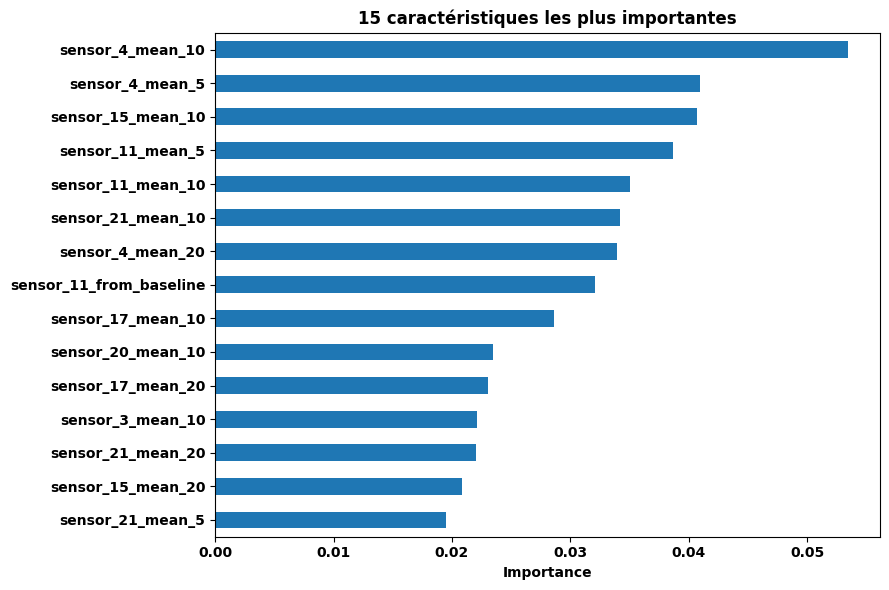

In [18]:
import joblib
import matplotlib.pyplot as plt

# Prépare le dernier cycle observé de chaque moteur du jeu de test.
test_path = os.path.join(RAW_DATA_DIR, f"test_{DATASET_ID}.txt")
rul_path = os.path.join(RAW_DATA_DIR, f"RUL_{DATASET_ID}.txt")
raw_test = pd.read_csv(test_path, sep=r"\s+", header=None, names=COLUMN_NAMES)
test_features = create_temporal_features(raw_test)
test_last = (
    test_features.sort_values(["unit_number", "time_in_cycles"])
    .groupby("unit_number", as_index=False)
    .tail(1)
    .sort_values("unit_number")
    .reset_index(drop=True)
)
X_test = test_last[FEATURE_COLUMNS].replace([np.inf, -np.inf], np.nan).fillna(0)
y_test = pd.read_csv(rul_path, sep=r"\s+", header=None, names=["RUL"])["RUL"]
assert len(X_test) == len(y_test), "Le nombre de moteurs test ne correspond pas aux cibles RUL."

# Évaluation du modèle final, entraîné sur tous les moteurs de train.
final_model = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    max_features="sqrt",
    n_jobs=-1,
    random_state=42,
)
final_model.fit(X, y)
test_predictions = final_model.predict(X_test)

print(f"MAE test officiel : {mean_absolute_error(y_test, test_predictions):.2f} cycles")
print(f"RMSE test officiel : {np.sqrt(mean_squared_error(y_test, test_predictions)):.2f} cycles")
print(f"Score NASA test officiel : {nasa_asymmetric_score(y_test, test_predictions):.2f}")

predictions = pd.DataFrame({
    "unit_number": test_last["unit_number"],
    "actual_RUL": y_test,
    "predicted_RUL": np.maximum(0, test_predictions).round(1),
})
predictions["decision"] = pd.cut(
    predictions["predicted_RUL"],
    bins=[-np.inf, 20, 25, 50, np.inf],
    labels=[
        "Alerte critique",
        "Surveillance renforcée",
        "Inspection planifiée",
        "Normal",
    ],
    right=True,
)
predictions_path = os.path.join(PROCESSED_DATA_DIR, f"predictions_test_{DATASET_ID}.csv")
predictions.to_csv(predictions_path, index=False)
display(predictions.head(30))
print(f"Prédictions sauvegardées : {predictions_path}")

# Sauvegarde du modèle et des colonnes nécessaires à l'inférence.
MODEL_DIR = os.path.join("..", "models")
os.makedirs(MODEL_DIR, exist_ok=True)
model_path = os.path.join(MODEL_DIR, f"random_forest_{DATASET_ID}.joblib")
joblib.dump({"model": final_model, "feature_columns": FEATURE_COLUMNS}, model_path)
print(f"Modèle sauvegardé : {model_path}")

# Variables les plus utiles selon le modèle.
importance = pd.Series(final_model.feature_importances_, index=FEATURE_COLUMNS)
importance = importance.sort_values(ascending=False).head(15).sort_values()
importance.plot(kind="barh", figsize=(9, 6), title="15 caractéristiques les plus importantes")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score

# Horizon d'alerte exprime en cycles, car le jeu CMAPSS ne fournit pas de dates.
ALERT_HORIZON_CYCLES = 30
ALERT_PROBABILITY_THRESHOLD = 0.5

# unit_number identifie le moteur; il sert au groupement et au reporting,
# mais n'est pas une caractéristique du modèle.
assert "unit_number" not in FEATURE_COLUMNS

y_alert = (df_features["RUL"] <= ALERT_HORIZON_CYCLES).astype("int8")

alert_model = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=42,
)

# Validation sur les mêmes moteurs séparés que pour la régression RUL.
X_alert_train = X.iloc[train_indices].astype(np.float32, copy=False)
X_alert_validation = X.iloc[validation_indices].astype(np.float32, copy=False)
y_alert_train = y_alert.iloc[train_indices]
y_alert_validation = y_alert.iloc[validation_indices]

alert_model.fit(X_alert_train, y_alert_train)
validation_probability = alert_model.predict_proba(X_alert_validation)[:, 1]
validation_prediction = (
    validation_probability >= ALERT_PROBABILITY_THRESHOLD
).astype("int8")

print(f"Horizon d'alerte : {ALERT_HORIZON_CYCLES} cycles")
print(f"Moteurs en validation : {len(validation_units)}")
print("Matrice de confusion (lignes = réel, colonnes = prédit) :")
print(confusion_matrix(y_alert_validation, validation_prediction, labels=[0, 1]))
print(classification_report(
    y_alert_validation,
    validation_prediction,
    labels=[0, 1],
    target_names=["Pas de panne imminente", "Panne dans l'horizon"],
    zero_division=0,
))
print(
    "Average precision validation : "
    f"{average_precision_score(y_alert_validation, validation_probability):.3f}"
)

# Réentraînement sur tous les moteurs d'entraînement, puis test officiel.
final_alert_model = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=42,
)
final_alert_model.fit(X.astype(np.float32, copy=False), y_alert)
test_alert_probability = final_alert_model.predict_proba(
    X_test.astype(np.float32, copy=False)
)[:, 1]
test_alert_prediction = (
    test_alert_probability >= ALERT_PROBABILITY_THRESHOLD
).astype("int8")
y_test_alert = (y_test <= ALERT_HORIZON_CYCLES).astype("int8")

print("Évaluation officielle par moteur :")
print(confusion_matrix(y_test_alert, test_alert_prediction, labels=[0, 1]))
print(classification_report(
    y_test_alert,
    test_alert_prediction,
    labels=[0, 1],
    target_names=["Pas de panne imminente", "Panne dans l'horizon"],
    zero_division=0,
))
print(
    "Average precision test : "
    f"{average_precision_score(y_test_alert, test_alert_probability):.3f}"
)

# Le numéro moteur reste la clé d'équipement dans les résultats.
predictions["failure_within_horizon"] = np.where(
    test_alert_prediction == 1, "Oui", "Non"
)
predictions["failure_probability"] = test_alert_probability.round(4)
predictions["alert_horizon_cycles"] = ALERT_HORIZON_CYCLES
predictions.to_csv(predictions_path, index=False)

alert_model_path = os.path.join(
    MODEL_DIR, f"random_forest_alert_{DATASET_ID}.joblib"
)
joblib.dump({
    "model": final_alert_model,
    "feature_columns": FEATURE_COLUMNS,
    "alert_horizon_cycles": ALERT_HORIZON_CYCLES,
    "probability_threshold": ALERT_PROBABILITY_THRESHOLD,
}, alert_model_path)
print(f"Prédictions avec alertes sauvegardées : {predictions_path}")
print(f"Classifieur d'alerte sauvegardé : {alert_model_path}")
display(predictions[[
    "unit_number",
    "actual_RUL",
    "predicted_RUL",
    "failure_within_horizon",
    "failure_probability",
    "alert_horizon_cycles",
]].head(10))

Horizon d'alerte : 30 cycles
Moteurs en validation : 20
Matrice de confusion (lignes = réel, colonnes = prédit) :
[[3416   34]
 [  58  562]]
                        precision    recall  f1-score   support

Pas de panne imminente       0.98      0.99      0.99      3450
  Panne dans l'horizon       0.94      0.91      0.92       620

              accuracy                           0.98      4070
             macro avg       0.96      0.95      0.96      4070
          weighted avg       0.98      0.98      0.98      4070

Average precision validation : 0.984
Évaluation officielle par moteur :
[[73  2]
 [ 6 19]]
                        precision    recall  f1-score   support

Pas de panne imminente       0.92      0.97      0.95        75
  Panne dans l'horizon       0.90      0.76      0.83        25

              accuracy                           0.92       100
             macro avg       0.91      0.87      0.89       100
          weighted avg       0.92      0.92      0.92      

,unit_number,actual_RUL,predicted_RUL,failure_within_horizon,failure_probability,alert_horizon_cycles
0,1,112,166.2,Non,0.0000,30
1,2,98,147.3,Non,0.0000,30
2,3,69,61.5,Non,0.0686,30
3,4,82,97.5,Non,0.0064,30
4,5,91,108.7,Non,0.0000,30
5,6,93,141.9,Non,0.0000,30
6,7,91,117.3,Non,0.0000,30
7,8,95,93.9,Non,0.0067,30
8,9,111,127.2,Non,0.0000,30
9,10,96,107.0,Non,0.0000,30


In [10]:
print("Nombre de features :", len(FEATURE_COLUMNS))
print("\nListe complète des features :")
for i, feature in enumerate(FEATURE_COLUMNS, start=1):
    print(f"{i:3}. {feature}")

Nombre de features : 155

Liste complète des features :
  1. sensor_2
  2. sensor_3
  3. sensor_4
  4. sensor_5
  5. sensor_6
  6. sensor_7
  7. sensor_8
  8. sensor_9
  9. sensor_11
 10. sensor_12
 11. sensor_13
 12. sensor_14
 13. sensor_15
 14. sensor_16
 15. sensor_17
 16. sensor_20
 17. sensor_21
 18. setting_1
 19. setting_2
 20. sensor_2_delta
 21. sensor_2_from_baseline
 22. sensor_2_mean_5
 23. sensor_2_std_5
 24. sensor_2_mean_10
 25. sensor_2_std_10
 26. sensor_2_mean_20
 27. sensor_2_std_20
 28. sensor_3_delta
 29. sensor_3_from_baseline
 30. sensor_3_mean_5
 31. sensor_3_std_5
 32. sensor_3_mean_10
 33. sensor_3_std_10
 34. sensor_3_mean_20
 35. sensor_3_std_20
 36. sensor_4_delta
 37. sensor_4_from_baseline
 38. sensor_4_mean_5
 39. sensor_4_std_5
 40. sensor_4_mean_10
 41. sensor_4_std_10
 42. sensor_4_mean_20
 43. sensor_4_std_20
 44. sensor_5_delta
 45. sensor_5_from_baseline
 46. sensor_5_mean_5
 47. sensor_5_std_5
 48. sensor_5_mean_10
 49. sensor_5_std_10
 50. senso

In [9]:
errors = test_predictions - y_test

print("========================================")
print("ANALYSE DES ERREURS")
print("========================================")

print(f"Erreur moyenne              : {errors.mean():.2f}")
print(f"Erreur absolue moyenne      : {np.abs(errors).mean():.2f}")
print(f"Surestimations              : {(errors > 0).sum()}")
print(f"Sous-estimations            : {(errors < 0).sum()}")
print(f"Surestimation moyenne       : {errors[errors > 0].mean():.2f}")
print(f"Sous-estimation moyenne     : {errors[errors < 0].mean():.2f}")
print(f"Erreur maximale             : {errors.max():.2f}")
print(f"Erreur minimale             : {errors.min():.2f}")

ANALYSE DES ERREURS
Erreur moyenne              : 15.99
Erreur absolue moyenne      : 19.44
Surestimations              : 85
Sous-estimations            : 15
Surestimation moyenne       : 20.84
Sous-estimation moyenne     : -11.51
Erreur maximale             : 111.19
Erreur minimale             : -39.84


In [10]:
comparison = pd.DataFrame({
    "actual_RUL": y_test.values,
    "predicted_RUL": test_predictions,
})

comparison["error"] = (
    comparison["predicted_RUL"]
    - comparison["actual_RUL"]
)

comparison["absolute_error"] = (
    comparison["error"].abs()
)

print(
    comparison
    .sort_values("absolute_error", ascending=False)
    .head(20)
)

    actual_RUL  predicted_RUL       error  absolute_error
14          83     194.190446  111.190446      111.190446
77         107     199.262245   92.262245       92.262245
49          79     142.035388   63.035388       63.035388
72         131     189.730354   58.730354       58.730354
0          112     166.195171   54.195171       54.195171
15          84     135.635739   51.635739       51.635739
64         128     178.807886   50.807886       50.807886
66          77     127.377853   50.377853       50.377853
1           98     147.292857   49.292857       49.292857
5           93     141.940266   48.940266       48.940266
78          63     109.745886   46.745886       46.745886
74         113     159.119340   46.119340       46.119340
22         113     157.414975   44.414975       44.414975
53          97     138.254835   41.254835       41.254835
98         117     157.486164   40.486164       40.486164
32         106     145.939783   39.939783       39.939783
92          85

In [11]:
comparison["rul_range"] = pd.cut(
    comparison["actual_RUL"],
    bins=[0, 20, 40, 60, 80, 100, 150, np.inf],
    labels=[
        "0-20",
        "21-40",
        "41-60",
        "61-80",
        "81-100",
        "101-150",
        "150+"
    ]
)

summary = comparison.groupby("rul_range", observed=True).agg(
    n=("actual_RUL", "count"),
    MAE=("absolute_error", "mean"),
    mean_error=("error", "mean")
)

print(summary)

            n        MAE  mean_error
rul_range                           
0-20       16   3.759196    3.654156
21-40      12   8.939401    5.756510
41-60      11   8.525940    8.485843
61-80       6  36.546386   34.033137
81-100     22  26.086444   21.886560
101-150    33  26.953030   20.967852


In [12]:
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# Classification métier basée sur la RUL réelle ou estimée.
def classify_rul(rul):
    if rul <= 20:
        return "Critique"
    elif rul <= 25:
        return "Surveillance renforcée"
    elif rul <= 50:
        return "Inspection planifiée"
    else:
        return "Normal"

comparison["actual_class"] = comparison["actual_RUL"].apply(classify_rul)
comparison["predicted_class"] = comparison["predicted_RUL"].apply(classify_rul)

labels = [
    "Critique",
    "Surveillance renforcée",
    "Inspection planifiée",
    "Normal",
]

cm = confusion_matrix(
    comparison["actual_class"],
    comparison["predicted_class"],
    labels=labels
)

cm_df = pd.DataFrame(
    cm,
    index=[f"Réel : {label}" for label in labels],
    columns=[f"Prédit : {label}" for label in labels]
)

print("========================================")
print("MATRICE DE CONFUSION")
print("========================================")
display(cm_df)

print("\n========================================")
print("RAPPORT DE CLASSIFICATION")
print("========================================")
print(
    classification_report(
        comparison["actual_class"],
        comparison["predicted_class"],
        labels=labels,
        zero_division=0
    )
)

MATRICE DE CONFUSION


,Prédit : Critique,Prédit : Surveillance renforcée,Prédit : Inspection planifiée,Prédit : Normal
Réel : Critique,11,4,1,0
Réel : Surveillance renforcée,1,0,2,0
Réel : Inspection planifiée,0,1,9,4
Réel : Normal,0,0,1,66



RAPPORT DE CLASSIFICATION
                        precision    recall  f1-score   support

              Critique       0.92      0.69      0.79        16
Surveillance renforcée       0.00      0.00      0.00         3
  Inspection planifiée       0.69      0.64      0.67        14
                Normal       0.94      0.99      0.96        67

              accuracy                           0.86       100
             macro avg       0.64      0.58      0.60       100
          weighted avg       0.88      0.86      0.86       100



In [13]:
missed_critical = comparison[
    (comparison["actual_RUL"] <= 20) &
    (comparison["predicted_RUL"] > 20)
]

print(missed_critical[
    ["actual_RUL", "predicted_RUL", "error"]
].sort_values("actual_RUL"))

    actual_RUL  predicted_RUL      error
40          18      40.579845  22.579845
35          19      24.102651   5.102651
23          20      22.961772   2.961772
91          20      22.987593   2.987593
99          20      21.283709   1.283709


## 6. Inférence batch et suivi en production

Le modèle et la liste ordonnée des features sont exportés pour l'inférence. La fonction ci-dessous accepte l'historique disponible de chaque moteur et prédit sa RUL au dernier cycle. En production, il faut conserver au minimum l'historique nécessaire aux fenêtres glissantes et suivre la dérive des capteurs; le déploiement Kafka et le réentraînement automatique ne sont pas configurés dans ce notebook.

In [ ]:
def infer_fleet_rul(raw_data: pd.DataFrame, model, feature_columns: list[str]) -> pd.DataFrame:
    """Prédit la RUL et la décision de maintenance au dernier cycle de chaque moteur."""
    featured = create_temporal_features(raw_data)
    latest = (
        featured.sort_values(["unit_number", "time_in_cycles"])
        .groupby("unit_number", as_index=False)
        .tail(1)
        .sort_values("unit_number")
        .reset_index(drop=True)
    )
    latest_X = latest[feature_columns].replace([np.inf, -np.inf], np.nan).fillna(0)
    latest["predicted_RUL"] = np.maximum(0, model.predict(latest_X))
    latest["decision"] = pd.cut(
        latest["predicted_RUL"],
        bins=[-np.inf, 20, 25, 50, np.inf],
        labels=[
            "Alerte critique",
            "Surveillance renforcée",
            "Inspection planifiée",
            "Normal",
        ],
        right=True,
    )
    return latest[["unit_number", "time_in_cycles", "predicted_RUL", "decision"]]


# Vérifie le flux d'inférence batch sur les moteurs du jeu de test.
batch_predictions = infer_fleet_rul(raw_test, final_model, FEATURE_COLUMNS)
display(batch_predictions.head(10))


def sensor_drift_report(reference_data: pd.DataFrame, current_data: pd.DataFrame) -> pd.DataFrame:
    """Signale les décalages de moyenne capteur, à comparer à régime équivalent."""
    reference_mean = reference_data[selected_sensors].mean()
    reference_std = reference_data[selected_sensors].std(ddof=0).replace(0, np.nan)
    current_mean = current_data[selected_sensors].mean()
    standardized_shift = ((current_mean - reference_mean) / reference_std).abs()
    return pd.DataFrame({
        "absolute_mean_shift_in_std": standardized_shift,
        "drift_alert": standardized_shift > 0.5,
    }).sort_values("absolute_mean_shift_in_std", ascending=False)


# Pour un suivi réel, appeler ce rapport périodiquement sur des fenêtres récentes
# comparables au régime de référence, et déclencher une revue si une alerte apparaît.

In [ ]:
def infer_fleet_alerts(
    raw_data: pd.DataFrame,
    model,
    feature_columns: list[str],
    horizon_cycles: int = ALERT_HORIZON_CYCLES,
    probability_threshold: float = ALERT_PROBABILITY_THRESHOLD,
) -> pd.DataFrame:
    """Retourne une alerte par moteur à son dernier cycle observé."""
    featured = create_temporal_features(raw_data)
    latest = (
        featured.sort_values(["unit_number", "time_in_cycles"])
        .groupby("unit_number", as_index=False)
        .tail(1)
        .sort_values("unit_number")
        .reset_index(drop=True)
    )
    latest_X = (
        latest[feature_columns]
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0)
        .astype(np.float32, copy=False)
    )
    latest["failure_probability"] = model.predict_proba(latest_X)[:, 1]
    latest["failure_within_horizon"] = np.where(
        latest["failure_probability"] >= probability_threshold, "Oui", "Non"
    )
    latest["alert_horizon_cycles"] = horizon_cycles
    return latest[[
        "unit_number",
        "time_in_cycles",
        "failure_within_horizon",
        "failure_probability",
        "alert_horizon_cycles",
    ]]


# unit_number est le numéro du moteur utilisé comme identifiant d'équipement.
batch_alert_predictions = infer_fleet_alerts(
    raw_test, final_alert_model, FEATURE_COLUMNS
)
display(batch_alert_predictions.head(10))

In [ ]:
import matplotlib.pyplot as plt

# Visualisation du moteur n°1 à partir des données traitées dans ce notebook.
engine_1 = df_train[df_train["unit_number"] == 1]
last_cycle = int(engine_1["time_in_cycles"].max())

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

axes[0].plot(engine_1["time_in_cycles"], engine_1["sensor_2"], color="tab:red", linewidth=2)
axes[0].set_ylabel("Température (Sensor 2)")
axes[0].set_title(f"Moteur 1 : évolution des capteurs jusqu'au cycle {last_cycle}")
axes[0].grid(True)

axes[1].plot(engine_1["time_in_cycles"], engine_1["sensor_11"], color="tab:blue", linewidth=2)
axes[1].set_ylabel("Pression (Sensor 11)")
axes[1].grid(True)

axes[2].plot(engine_1["time_in_cycles"], engine_1["RUL"], color="tab:green", linewidth=2)
axes[2].set_ylabel("RUL (cycles restants)")
axes[2].set_xlabel("Cycles de fonctionnement")
axes[2].grid(True)

plt.tight_layout()
plt.show()